# Studiul de caz 3 - Fac variabilele din graf explicațiile fraudei mai stabile?

Master - Rețele neuronale și deep learning (NN) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/cases/C3_shap_stability')

In [2]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Diaconu, I. D. și Pele, D. T. (2026). SHAP stability across random and forward-time validation in graph-augmented fraud detection.
Manuscris trimis la *Expert Systems with Applications*; cod: github.com/QuantLet/GNN_XAI_Stability. Lucrarea continuă studiul
Diaconu și Pele (2026), *Explainable AI in financial fraud detection: Evidence from the IEEE-CIS fraud dataset*, PICBE 20(1), 118-132, doi:10.2478/picbe-2026-0015 (studiul de caz 1).

**Conținutul notebook-ului.** (1) Antrenăm trei clasificatori XGBoost (*eXtreme Gradient Boosting*) care diferă numai prin variabilele de intrare: numai variabilele tranzacției (modelul tabelar),
aceleași variabile plus o reprezentare (*embedding*) cu 64 de dimensiuni produsă de o rețea neuronală pe grafuri (GNN) de tip GraphSAGE (modelul cu graf) și aceleași variabile plus 64 de coloane
gaussiene cu aceeași covarianță ca reprezentarea (controlul gaussian). (2) Estimăm fiecare model pe o împărțire aleatoare și pe o împărțire înainte în timp, cu mai multe semințe aleatoare.
(3) Explicăm aceleași tranzacții din eșantionul de evaluare cu SHAP (*SHapley Additive exPlanations*) și măsurăm cît se deplasează explicațiile variabilelor originale între cele două scheme de validare,
cît se micșorează ele cînd se adaugă coloane noi și dacă motivul principal al unei tranzacții rămîne același.

**Adaptarea pentru curs.** Lucrarea folosește datele de fraudă cu carduri IEEE-CIS (*Institute of Electrical and Electronics Engineers, Computational Intelligence Society*), 486 de variabile,
un graf eterogen de plăți și entități și 20 de reestimări. Noi folosim graful tranzacțiilor Bitcoin Elliptic din cursul 9 (203.769 de tranzacții, 165 de variabile,
fluxurile de plăți ca muchii), 8 reestimări, arbori mai mici și 1.000 de tranzacții explicate pentru fiecare schemă de validare. Măsurile (divergența Jensen-Shannon, distanța Wasserstein pe trei scale,
concordanța primelor k variabile, ponderea masei SHAP) urmează secțiunile 3.4-3.7 din lucrare.

## 1. Datele: graful tranzacțiilor Elliptic și cele două scheme de validare

203,769 transactions, 234,355 edges, 46,564 labelled (4,545 illicit, 42,019 licit), 49 time steps
forward-time split: train 29,894 (illicit 11.6 %), test 16,670 (illicit 6.5 %)


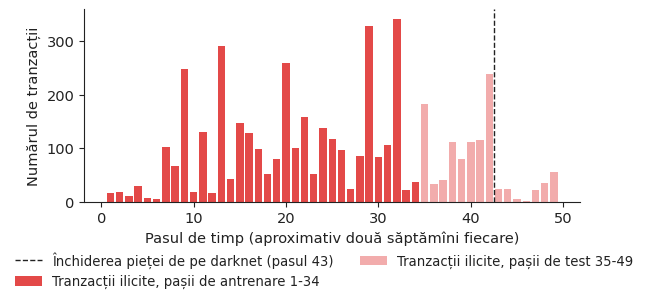

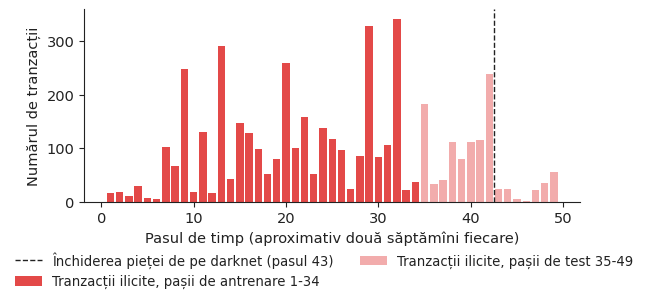

In [3]:
os.environ["OMP_NUM_THREADS"] = "1"          # torch and xgboost in the same process
import torch                                 # torch before sklearn / shap
torch.set_num_threads(4)
import time, urllib.request, xgboost as xgb, shap
from torch_geometric.nn import SAGEConv
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from scipy import stats

RAW = os.path.join(cu.REPO, "data", "raw", "elliptic")       # on demand: python3 data/download_all.py elliptic
FILES = ["elliptic_txs_features.csv.zip", "elliptic_txs_edgelist.csv.zip", "elliptic_txs_classes.csv.zip"]
os.makedirs(RAW, exist_ok=True)
for fn in FILES:                                              # same files as torch_geometric.datasets.EllipticBitcoinDataset
    if not os.path.exists(os.path.join(RAW, fn)):
        urllib.request.urlretrieve("https://data.pyg.org/datasets/elliptic/" + fn, os.path.join(RAW, fn))
F = pd.read_csv(os.path.join(RAW, FILES[0]), header=None)
E = pd.read_csv(os.path.join(RAW, FILES[1]))
C = pd.read_csv(os.path.join(RAW, FILES[2]))
F.columns = ["txId", "step"] + [f"f{i}" for i in range(1, 166)]
FEATS = list(F.columns[2:])                                   # 165 features: 93 local + 72 aggregated over neighbours; the time step is not used as a feature
pos = pd.Series(np.arange(len(F)), index=F.txId)
y = C.set_index("txId")["class"].astype(str).reindex(F.txId).map({"1": 1, "2": 0, "unknown": -1}).values
step = F.step.values
X = F[FEATS].values.astype(np.float32)
ei = torch.tensor(np.vstack([pos[E.txId1].values, pos[E.txId2].values]), dtype=torch.long)
ei = torch.cat([ei, ei.flip(0)], 1)                           # payment flows as undirected edges for message passing
lab = y >= 0
CUT, SHUT = 34, 43                                            # train on time steps 1-34 (Weber et al., 2019); dark-market shutdown at step 43
TR_T, TE_T = lab & (step <= CUT), lab & (step > CUT)          # forward-time split (fixed)
print(f"{len(F):,} transactions, {E.shape[0]:,} edges, {lab.sum():,} labelled ({(y == 1).sum():,} illicit, {(y == 0).sum():,} licit), 49 time steps")
print(f"forward-time split: train {TR_T.sum():,} (illicit {100 * y[TR_T].mean():.1f} %), test {TE_T.sum():,} (illicit {100 * y[TE_T].mean():.1f} %)")

cnt = pd.DataFrame({"step": step[lab], "y": y[lab]}).groupby("step").y.agg(["sum", "count"])
def fig_steps(lang):
    fig, ax = plt.subplots(figsize=(6.4, 2.5))
    ax.bar(cnt.index[cnt.index <= CUT], cnt["sum"][cnt.index <= CUT], color=cu.EVENT, width=0.8,
           label=cu.T(lang, "Illicit transactions, training steps 1-34", "Tranzacții ilicite, pașii de antrenare 1-34"))
    ax.bar(cnt.index[cnt.index > CUT], cnt["sum"][cnt.index > CUT], color=cu.EVENT, alpha=0.45, width=0.8,
           label=cu.T(lang, "Illicit transactions, test steps 35-49", "Tranzacții ilicite, pașii de test 35-49"))
    ax.axvline(SHUT - 0.5, color=cu.INK, ls="--", lw=1, label=cu.T(lang, "Dark-market shutdown (step 43)", "Închiderea pieței de pe darknet (pasul 43)"))
    ax.set_xlabel(cu.T(lang, "Time step (about two weeks each)", "Pasul de timp (aproximativ două săptămîni fiecare)"))
    ax.set_ylabel(cu.T(lang, "Number of transactions", "Numărul de tranzacții"))
    cu.legend_bottom(fig, ncol=2, y=-0.04)
    return fig
cu.save_both(fig_steps, "f1_steps")

## 2. Cele trei modele: tabelar, cu graf (reprezentare GraphSAGE) și controlul gaussian

In [4]:
class SAGE(torch.nn.Module):
    """Two-layer GraphSAGE with mean aggregation, 64 hidden units, linear two-class head (paper Section 3.3)."""
    def __init__(self, d, h=64):
        super().__init__()
        self.c1, self.c2, self.head = SAGEConv(d, h), SAGEConv(h, h), torch.nn.Linear(h, 2)
    def forward(self, x, e):
        z1 = torch.relu(self.c1(x, e))
        return self.head(torch.relu(self.c2(z1, e))), z1

EPOCHS, LR, WD = 120, 2e-3, 1e-4
def gnn_embedding(train, graph_nodes, seed):
    """Train GraphSAGE on the labels of `train` only, with messages among `graph_nodes`; freeze; return the first-layer embedding z1
    of every transaction. Scaling uses the training rows only."""
    torch.manual_seed(seed)
    mu, sd = X[train].mean(0), X[train].std(0) + 1e-6
    x = torch.tensor((X - mu) / sd)
    keep = torch.tensor(graph_nodes)
    e_tr = ei[:, keep[ei[0]] & keep[ei[1]]]
    m = SAGE(X.shape[1])
    opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WD)
    yt, tm = torch.tensor(np.where(y < 0, 0, y)), torch.tensor(train)
    w = torch.tensor([1.0, (y[train] == 0).sum() / (y[train] == 1).sum()], dtype=torch.float32)   # weighted cross-entropy
    for _ in range(EPOCHS):
        m.train(); opt.zero_grad()
        out, _ = m(x, e_tr)
        torch.nn.functional.cross_entropy(out[tm], yt[tm], weight=w).backward()
        opt.step()
    m.eval()
    with torch.no_grad():
        _, z = m(x, ei)
    return z.numpy()

def gaussian_control(Z, train, seed):
    """64 Gaussian columns with the training covariance of the embedding: G = U L', U ~ N(0, I), L L' = Cov(Z_train) + 1e-6 I."""
    L = np.linalg.cholesky(np.cov(Z[train].T) + 1e-6 * np.eye(Z.shape[1]))
    return (np.random.default_rng(10_000 + seed).standard_normal(Z.shape) @ L.T).astype(np.float32)

XGB = dict(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=2, random_state=0)
def fit_explain(M, train, test_rows, bg_rows):
    clf = xgb.XGBClassifier(**XGB).fit(M[train], y[train])
    ex = shap.TreeExplainer(clf, data=M[bg_rows], feature_perturbation="interventional", model_output="raw")   # interventional TreeSHAP, raw margin
    return clf, ex.shap_values(M[test_rows], check_additivity=False).astype(np.float32)

def strat_sample(mask, n, seed):
    """Sample n rows of `mask`, stratified by class (proportional)."""
    rng = np.random.default_rng(seed)
    idx = np.flatnonzero(mask); out = []
    for c in (0, 1):
        ic = idx[y[idx] == c]
        out.append(rng.choice(ic, int(round(n * len(ic) / len(idx))), replace=False))
    return np.sort(np.concatenate(out))

SEEDS = list(range(1, 9))          # 8 refits: each seed changes the random split, the GNN initialisation and the Gaussian draws
N_EXPL, N_BG = 1000, 100
test_T = strat_sample(TE_T, N_EXPL, 2026)                     # the same 1,000 later transactions for every forward-time fit
CACHE = "cache"; os.makedirs(CACHE, exist_ok=True)

def run_seed(s):
    f = os.path.join(CACHE, f"seed{s}.npz")
    if os.path.exists(f):
        return dict(np.load(f))
    rng = np.random.default_rng(s)
    lab_idx = np.flatnonzero(lab)
    hold = strat_sample(lab, TE_T.sum(), 100 + s)             # random split: holdout of the same size as the forward-time test
    TE_R = np.zeros(len(y), bool); TE_R[hold] = True
    TR_R = lab & ~TE_R
    test_R = strat_sample(TE_R, N_EXPL, 200 + s)
    torch.set_num_threads(2)
    import contextlib, warnings
    warnings.filterwarnings("ignore")
    out = {}
    for reg, tr, te_rows, gnodes in (("R", TR_R, test_R, np.ones(len(y), bool)), ("T", TR_T, test_T, step <= CUT)):
        bg = strat_sample(tr, N_BG, 300 + s)                  # SHAP background: 100 training rows
        Z = gnn_embedding(tr, gnodes, s)
        G = gaussian_control(Z, tr, s)
        for m, M in (("B", X), ("G", np.hstack([X, Z])), ("C", np.hstack([X, G]))):   # B tabular, G graph, C Gaussian control
            with open(os.devnull, "w") as dn, contextlib.redirect_stderr(dn):   # no SHAP progress bars from the workers
                clf, sv = fit_explain(M, tr, te_rows, bg)
            out[f"sv_{m}{reg}"] = sv
            if reg == "T":
                out[f"p_{m}"] = clf.predict_proba(M[TE_T])[:, 1].astype(np.float32)
    np.savez_compressed(f, **out)
    return out

from joblib import Parallel, delayed
os.environ["PYTHONWARNINGS"] = "ignore"                       # quiet worker processes
t0 = time.time()
RES = dict(zip(SEEDS, Parallel(n_jobs=4)(delayed(run_seed)(s) for s in SEEDS)))   # 4 refits in parallel, 2 threads each
print(f"{len(SEEDS)} refits x 2 validation schemes x 3 models, {time.time() - t0:.0f} s (cached in {CACHE}/)")

8 refits x 2 validation schemes x 3 models, 9 s (cached in cache/)


## 3. Se deplasează mai mult explicațiile variabilelor originale cu graful? (divergența Jensen-Shannon)

In [5]:
K = len(FEATS)                                                # shared original features
def js_pair(a_R, a_T, b_R, b_T):
    """Paper eq. (1)-(2): per feature, 50 quantile bins from the 4 pooled samples, JS divergence (nats) between random and forward-time
    SHAP histograms for model a and for model b; returns the mean over features of J_a - J_b."""
    d = []
    for k in range(K):
        pool = np.concatenate([a_R[:, k], a_T[:, k], b_R[:, k], b_T[:, k]])
        e = np.unique(np.quantile(pool, np.linspace(0, 1, 51)))
        if len(e) < 3:
            e = np.linspace(pool.min(), pool.max() + 1e-12, 51)
        def J(P, Q):
            p = np.histogram(P, e)[0] / len(P); q = np.histogram(Q, e)[0] / len(Q); m_ = (p + q) / 2
            return 0.5 * np.sum(p[p > 0] * np.log(p[p > 0] / m_[p > 0])) + 0.5 * np.sum(q[q > 0] * np.log(q[q > 0] / m_[q > 0]))
        d.append(J(a_R[:, k], a_T[:, k]) - J(b_R[:, k], b_T[:, k]))
    return float(np.mean(d))

def wass(a_R, a_T):
    """Paper eq. (4)-(5): empirical 1-Wasserstein distance per feature and pooled mean absolute contribution."""
    W = np.mean(np.abs(np.sort(a_R, 0) - np.sort(a_T, 0)), 0)
    A = 0.5 * (np.mean(np.abs(a_R), 0) + np.mean(np.abs(a_T), 0))
    return W, A
def ratio(W, A):
    return np.where(A > 0, W / np.where(A > 0, A, 1), 0.0)

def top_overlap(a, b, k):
    """Paper eq. (3): mean share of the k leading features (by |SHAP|) of model a that are also among the k leading features of model b."""
    ta, tb = np.argsort(-np.abs(a), 1)[:, :k], np.argsort(-np.abs(b), 1)[:, :k]
    return np.mean([len(set(ta[i]) & set(tb[i])) / k for i in range(len(a))])

rows = []
for s in SEEDS:
    r = RES[s]; sh = {k[3:]: v[:, :K] for k, v in r.items() if k.startswith("sv_")}       # original features only
    WB, AB = wass(sh["BR"], sh["BT"]); WG, AG = wass(sh["GR"], sh["GT"]); WC, AC = wass(sh["CR"], sh["CT"])
    full = {k[3:]: v for k, v in r.items() if k.startswith("sv_")}
    mass = lambda m: np.mean([np.abs(full[m + g][:, K:]).sum() / np.abs(full[m + g]).sum() for g in "RT"])
    sumabs = lambda m: np.mean([np.abs(sh[m + g]).sum(1).mean() for g in "RT"])
    act = (AG > 0) & (AB > 0)
    rows.append(dict(seed=s,
        js_GC=js_pair(sh["GR"], sh["GT"], sh["CR"], sh["CT"]), js_GB=js_pair(sh["GR"], sh["GT"], sh["BR"], sh["BT"]),
        w_raw_GB=np.mean(WG - WB), w_raw_GC=np.mean(WG - WC),
        w_own_GB=np.mean(ratio(WG, AG) - ratio(WB, AB)), w_own_GC=np.mean(ratio(WG, AG) - ratio(WC, AC)),
        w_com_GB=np.mean(np.where((AG + AB) > 0, (WG - WB) / np.where((AG + AB) > 0, (AG + AB) / 2, 1), 0)),
        top10_G_R=10 * top_overlap(sh["GR"], sh["BR"], 10), top10_C_R=10 * top_overlap(sh["CR"], sh["BR"], 10),
        top10_G_T=10 * top_overlap(sh["GT"], sh["BT"], 10), top10_C_T=10 * top_overlap(sh["CT"], sh["BT"], 10),
        top3_G_T=3 * top_overlap(sh["GT"], sh["BT"], 3), top3_C_T=3 * top_overlap(sh["CT"], sh["BT"], 3),
        lead_G=100 * top_overlap(sh["GT"], sh["BT"], 1), lead_C=100 * top_overlap(sh["CT"], sh["BT"], 1),
        mass_G=100 * mass("G"), mass_C=100 * mass("C"),
        ratio_G=np.median(AG[act] / AB[act]), ratio_C=np.median(AC[(AC > 0) & (AB > 0)] / AB[(AC > 0) & (AB > 0)]),
        sum_B=sumabs("B"), sum_G=sumabs("G"), sum_C=sumabs("C")))
D = pd.DataFrame(rows).set_index("seed")
D["lead_G"], D["lead_C"] = 100 - D.lead_G, 100 - D.lead_C       # share of later transactions whose leading feature differs from the tabular model's

def ci(x):
    x = np.asarray(x, float); m = x.mean(); h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return m, m - h, m + h
for c in ["js_GC", "js_GB", "w_raw_GB", "w_own_GB", "w_com_GB", "w_own_GC"]:
    m, lo, hi = ci(D[c]); print(f"{c:9s} mean {m:+.5f}  95% CI [{lo:+.5f}, {hi:+.5f}]  positive in {(D[c] > 0).sum()}/{len(D)} refits")
D.round(4)

js_GC     mean +0.01390  95% CI [+0.00245, +0.02535]  positive in 6/8 refits
js_GB     mean +0.03518  95% CI [+0.02377, +0.04659]  positive in 8/8 refits
w_raw_GB  mean -0.01288  95% CI [-0.01537, -0.01039]  positive in 0/8 refits
w_own_GB  mean +0.06726  95% CI [+0.02226, +0.11226]  positive in 8/8 refits
w_com_GB  mean -0.45007  95% CI [-0.51273, -0.38741]  positive in 0/8 refits
w_own_GC  mean +0.01997  95% CI [-0.02013, +0.06006]  positive in 5/8 refits


,js_GC,js_GB,w_raw_GB,w_raw_GC,w_own_GB,w_own_GC,w_com_GB,top10_G_R,top10_C_R,top10_G_T,top10_C_T,top3_G_T,top3_C_T,lead_G,lead_C,mass_G,mass_C,ratio_G,ratio_C,sum_B,sum_G,sum_C
seed,,,,,,,,,,,,,,,,,,,,,,
1,0.0201,0.0526,-0.0103,-0.0113,0.1422,0.0618,-0.3931,6.435,8.183,6.701,8.029,2.010,2.387,41.6,18.4,54.704102,9.7965,0.5171,0.9489,9.8865,5.9880,9.4981
2,0.0026,0.0232,-0.0155,-0.0164,0.0110,-0.0122,-0.5745,6.470,8.191,6.553,7.890,1.723,2.435,59.0,18.6,57.477200,10.8683,0.5048,0.8988,9.7973,5.7050,9.4997
3,0.0291,0.0318,-0.0114,-0.0107,0.0629,0.0760,-0.4743,6.615,8.108,6.541,8.189,1.870,2.550,55.4,20.6,56.673599,10.3248,0.5062,0.9045,10.1426,5.7475,9.5886
4,-0.0045,0.0168,-0.0169,-0.0187,0.0040,-0.0515,-0.4402,6.405,8.247,6.570,7.939,1.792,2.460,55.0,21.6,54.745899,10.1497,0.5486,0.8787,10.2406,6.2078,9.7645
5,0.0243,0.0400,-0.0159,-0.0161,0.0649,0.0326,-0.4481,6.318,8.236,6.505,8.008,1.855,2.395,54.6,20.5,56.102299,8.4784,0.5152,0.9334,10.0819,5.8204,9.7809
6,0.0173,0.0442,-0.0089,-0.0104,0.1047,0.0023,-0.3716,6.474,7.681,6.485,7.754,1.782,2.465,58.6,17.2,55.185799,11.4342,0.5297,0.9131,9.9361,5.9459,9.5150
7,0.0261,0.0506,-0.0107,-0.0121,0.1288,0.0730,-0.3664,6.812,8.153,6.314,8.075,1.826,2.424,53.1,22.0,55.348999,10.2204,0.5218,0.9196,10.0121,5.9817,9.6106
8,-0.0038,0.0222,-0.0135,-0.0130,0.0196,-0.0223,-0.5322,6.684,8.013,6.650,8.148,1.844,2.490,52.4,22.0,56.165401,9.5097,0.4889,0.9242,9.9253,5.8368,9.7122


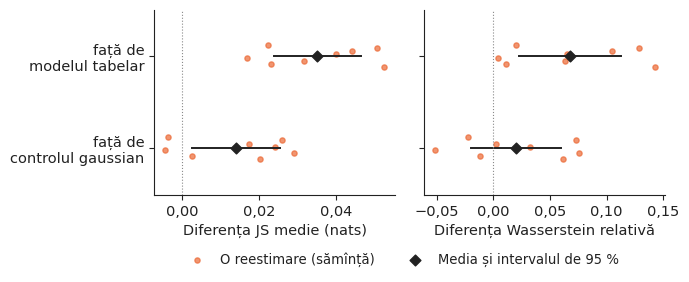

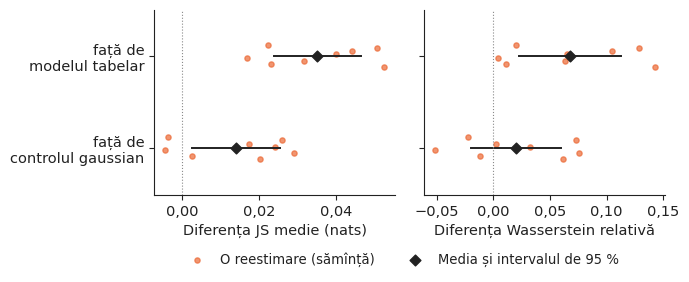

In [6]:
NAME = {"js_GC": ("JS: graph - Gaussian control", "JS: graf - control gaussian"),
        "js_GB": ("JS: graph - tabular", "JS: graf - tabelar"),
        "w_own_GB": ("Wasserstein, own scale: graph - tabular", "Wasserstein, scala proprie: graf - tabelar"),
        "w_own_GC": ("Wasserstein, own scale: graph - Gaussian", "Wasserstein, scala proprie: graf - gaussian")}
def fig_paired(lang):
    fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.4), sharey=True, gridspec_kw=dict(wspace=0.12))
    for ax, keys in zip(axs, (["js_GC", "js_GB"], ["w_own_GC", "w_own_GB"])):
        for j, c in enumerate(keys):
            ax.scatter(D[c], np.full(len(D), j) + np.linspace(-0.12, 0.12, len(D)), s=14, color=cu.PAL["DE_LU"], alpha=0.7,
                       label=cu.T(lang, "One refit (seed)", "O reestimare (sămînță)") if j == 0 else "_")
            m, lo, hi = ci(D[c])
            ax.plot([lo, hi], [j, j], color=cu.INK, lw=1.4)
            ax.scatter([m], [j], marker="D", s=30, color=cu.INK, zorder=3, label=cu.T(lang, "Mean and 95 % interval", "Media și intervalul de 95 %") if j == 0 else "_")
        ax.axvline(0, color=cu.MUTED, lw=0.8, ls=":")
        ax.set_ylim(-0.5, 1.5)
        cu.comma_axis(ax, lang, "x")
    axs[0].set_yticks([0, 1]); axs[0].set_yticklabels([cu.T(lang, "vs Gaussian\ncontrol", "față de\ncontrolul gaussian"), cu.T(lang, "vs tabular", "față de\nmodelul tabelar")])
    axs[0].set_xlabel(cu.T(lang, "Difference in mean JS (nats)", "Diferența JS medie (nats)"))
    axs[1].set_xlabel(cu.T(lang, "Difference in relative Wasserstein", "Diferența Wasserstein relativă"))
    cu.legend_bottom(fig, ncol=2, y=-0.08)
    return fig
cu.save_both(fig_paired, "f2_paired")

## 4. O tranzacție pe rînd: rămîne același motivul principal?

top10_G_R     6.527
top10_C_R     8.102
top10_G_T     6.540
top10_C_T     8.004
top3_G_T      1.838
top3_C_T      2.451
lead_G       53.712
lead_C       20.112
dtype: float64
share of |SHAP| on the added block (%): {'mass_G': 55.79999923706055, 'mass_C': 10.100000381469727}
median scale ratio vs tabular: {'ratio_G': 0.5170000195503235, 'ratio_C': 0.9150000214576721} | sum of |SHAP| of the original features per transaction: {'sum_B': 10.0, 'sum_C': 9.619999885559082, 'sum_G': 5.900000095367432}


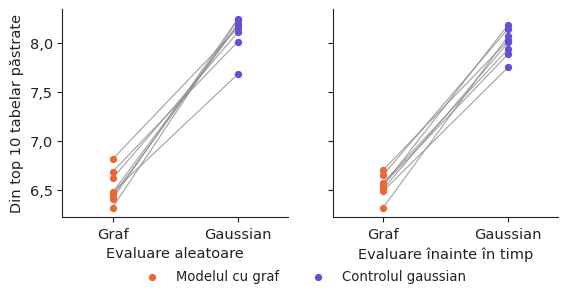

In [7]:
def fig_overlap(lang):
    fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.7), sharey=True)
    for ax, reg, ttl in zip(axs, "RT", (("Random holdout", "Evaluare aleatoare"), ("Forward-time holdout", "Evaluare înainte în timp"))):
        for s in SEEDS:
            ax.plot([0, 1], [D.loc[s, f"top10_G_{reg}"], D.loc[s, f"top10_C_{reg}"]], color=cu.MUTED, lw=0.8, alpha=0.8)
        ax.scatter(np.zeros(len(D)), D[f"top10_G_{reg}"], color=cu.PAL["DE_LU"], s=18, zorder=3, label=cu.T(lang, "Graph model", "Modelul cu graf"))
        ax.scatter(np.ones(len(D)), D[f"top10_C_{reg}"], color=cu.SERIES[6], s=18, zorder=3, label=cu.T(lang, "Gaussian control", "Controlul gaussian"))
        ax.set_xticks([0, 1]); ax.set_xticklabels([cu.T(lang, "Graph", "Graf"), cu.T(lang, "Gaussian", "Gaussian")]); ax.set_xlim(-0.4, 1.4)
        ax.set_xlabel(cu.T(lang, *ttl))
        cu.comma_axis(ax, lang)
    axs[0].set_ylabel(cu.T(lang, "Tabular top 10 retained", "Din top 10 tabelar păstrate"))
    cu.legend_bottom(fig, ncol=2, y=-0.04)
    return fig
cu.save_both(fig_overlap, "f3_overlap", headline=True)
print(D[["top10_G_R", "top10_C_R", "top10_G_T", "top10_C_T", "top3_G_T", "top3_C_T", "lead_G", "lead_C"]].mean().round(3))
print("share of |SHAP| on the added block (%):", D[["mass_G", "mass_C"]].mean().round(1).to_dict())
print("median scale ratio vs tabular:", D[["ratio_G", "ratio_C"]].mean().round(3).to_dict(),
      "| sum of |SHAP| of the original features per transaction:", D[["sum_B", "sum_C", "sum_G"]].mean().round(2).to_dict())

## 5. Calitatea detectării înainte și după închiderea pieței de pe darknet (pasul 43)

graph minus tabular AUC on steps 35-49: mean -0.0137, 95% CI [-0.0176, -0.0098]


,AUC,PRAUC,P,R,F1
label,,,,,
"(Tabular XGBoost, steps 35--42, XGBoost tabelar, pașii 35--42)",0.974,0.921,0.967,0.856,0.908
"(Tabular XGBoost, steps 43--49, XGBoost tabelar, pașii 43--49)",0.715,0.046,0.083,0.018,0.029
"(Graph model (XGBoost + GraphSAGE), steps 35--42, Model cu graf (XGBoost + GraphSAGE), pașii 35--42)",0.970,0.916,0.982,0.832,0.901
"(Graph model (XGBoost + GraphSAGE), steps 43--49, Model cu graf (XGBoost + GraphSAGE), pașii 43--49)",0.665,0.039,0.114,0.011,0.020
"(Gaussian control, steps 35--42, Controlul gaussian, pașii 35--42)",0.973,0.920,0.966,0.854,0.906
"(Gaussian control, steps 43--49, Controlul gaussian, pașii 43--49)",0.700,0.043,0.088,0.018,0.030


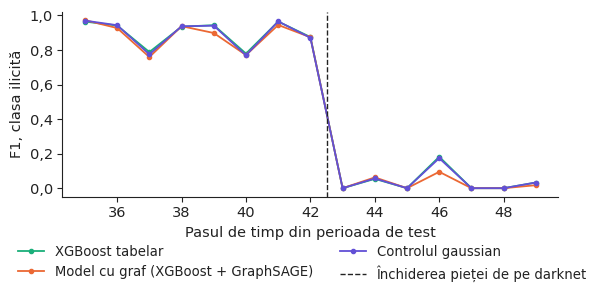

In [8]:
yT, sT = y[TE_T], step[TE_T]
MODELS = [("B", ("Tabular XGBoost", "XGBoost tabelar")), ("G", ("Graph model (XGBoost + GraphSAGE)", "Model cu graf (XGBoost + GraphSAGE)")),
          ("C", ("Gaussian control", "Controlul gaussian"))]
PER = [("pre", sT < SHUT, ("steps 35--42", "pașii 35--42")), ("post", sT >= SHUT, ("steps 43--49", "pașii 43--49"))]
perf = []
for m, nm in MODELS:
    for pk, msk, pn in PER:
        v = np.array([[roc_auc_score(yT[msk], RES[s][f"p_{m}"][msk]), average_precision_score(yT[msk], RES[s][f"p_{m}"][msk]),
                       precision_score(yT[msk], RES[s][f"p_{m}"][msk] > 0.5, zero_division=0), recall_score(yT[msk], RES[s][f"p_{m}"][msk] > 0.5),
                       f1_score(yT[msk], RES[s][f"p_{m}"][msk] > 0.5)] for s in SEEDS]).mean(0)
        perf.append(dict(model=m, per=pk, label=(f"{nm[0]}, {pn[0]}", f"{nm[1]}, {pn[1]}"), AUC=v[0], PRAUC=v[1], P=v[2], R=v[3], F1=v[4]))
P = pd.DataFrame(perf)
tab = P.set_index("label")[["AUC", "PRAUC", "P", "R", "F1"]]
cu.write_table(tab, "perf", [("Model, test period", "Model, perioada de test"), ("AUC", "AUC"), ("PR-AUC", "PR-AUC"),
                             ("Precision", "Precizie"), ("Recall", "Sensibilitate"), ("F1", "F1")], digits=3)
auc_d = np.array([roc_auc_score(yT, RES[s]["p_G"]) - roc_auc_score(yT, RES[s]["p_B"]) for s in SEEDS])
print("graph minus tabular AUC on steps 35-49: mean %+.4f, 95%% CI [%+.4f, %+.4f]" % ci(auc_d))
F1s = {m: pd.DataFrame({s: pd.Series(f1_score(yT[sT == t], RES[s][f"p_{m}"][sT == t] > 0.5) for t in range(CUT + 1, 50)) for s in SEEDS}).mean(1).values for m, _ in MODELS}
def fig_perf(lang):
    fig, ax = plt.subplots(figsize=(6.4, 2.4))
    for (m, nm), c in zip(MODELS, (cu.PAL["HU"], cu.PAL["DE_LU"], cu.SERIES[6])):
        ax.plot(range(CUT + 1, 50), F1s[m], marker="o", ms=3, color=c, label=cu.T(lang, *nm))
    ax.axvline(SHUT - 0.5, color=cu.INK, ls="--", lw=1, label=cu.T(lang, "Dark-market shutdown", "Închiderea pieței de pe darknet"))
    ax.set_xlabel(cu.T(lang, "Test time step", "Pasul de timp din perioada de test")); ax.set_ylabel(cu.T(lang, "F1, illicit class", "F1, clasa ilicită"))
    cu.comma_axis(ax, lang)
    cu.legend_bottom(fig, ncol=2, y=-0.04)
    return fig
cu.save_both(fig_perf, "f4_perf")
tab.round(3)

## 6. Tabelul de sinteză, cifrele pentru studiul de caz și rezumatul pentru slide

In [9]:
PAPER = {"js_GC": "+0.00534", "js_GB": "$-$0.00356", "w_raw_GB": "$-$0.00215", "w_own_GB": "+0.0451", "w_own_GC": "+0.0374", "w_com_GB": "$-$0.4833"}
LBL = {"js_GC": ("JS divergence, graph -- Gaussian control", "Divergența JS, graf -- control gaussian"),
       "js_GB": ("JS divergence, graph -- tabular", "Divergența JS, graf -- tabelar"),
       "w_raw_GB": ("Wasserstein, raw SHAP units, graph -- tabular", "Wasserstein, unități SHAP, graf -- tabelar"),
       "w_own_GB": ("Wasserstein, own scale, graph -- tabular", "Wasserstein, scala proprie, graf -- tabelar"),
       "w_own_GC": ("Wasserstein, own scale, graph -- Gaussian", "Wasserstein, scala proprie, graf -- gaussian"),
       "w_com_GB": ("Wasserstein, common scale, graph -- tabular", "Wasserstein, scală comună, graf -- tabelar")}
ND = {"js_GC": 4, "js_GB": 4, "w_raw_GB": 4, "w_own_GB": 3, "w_own_GC": 3, "w_com_GB": 3}
for lang in ("en", "ro"):
    F_ = lambda v, nd: cu.fmt(v, nd, lang, sign=True).replace("-", "$-$")
    out = ["\\begin{tabular}{lrrrr}", "\\toprule",
           cu.T(lang, "Paired difference (mean over refits)", "Diferența pereche (media reestimărilor)") + " & " +
           cu.T(lang, "Ours", "Noi") + " & " + cu.T(lang, "95\\,\\% interval", "Interval 95\\,\\%") + " & " +
           cu.T(lang, "Positive runs", "Rulări pozitive") + " & " + cu.T(lang, "Paper (IEEE-CIS)", "Lucrarea (IEEE-CIS)") + r" \\", "\\midrule"]
    for c in LBL:
        m, lo, hi = ci(D[c]); nd = ND[c]
        pv = PAPER[c] if lang == "en" else PAPER[c].replace(".", ",")
        out.append(f"{cu.T(lang, *LBL[c])} & {F_(m, nd)} & [{F_(lo, nd)}; {F_(hi, nd)}] & {(D[c] > 0).sum()}/{len(D)} & {pv} " + r"\\")
    out += ["\\bottomrule", "\\end{tabular}"]
    open(f"tab_stability_{lang}.tex", "w", encoding="utf-8").write("\n".join(out) + "\n")
print(open("tab_stability_en.tex").read())

mm = D.mean(); pre = P.set_index(["model", "per"])
cG, cB = ci(D.js_GC), ci(D.js_GB)
cu.write_numbers({
    "nTx": int(len(F)), "nEdges": int(E.shape[0]), "nIllicit": int((y == 1).sum()), "nLicit": int((y == 0).sum()), "nLab": int(lab.sum()),
    "nTrain": int(TR_T.sum()), "nTest": int(TE_T.sum()), "illTrain": 100 * y[TR_T].mean(), "illTest": 100 * y[TE_T].mean(),
    "nSeeds": len(SEEDS), "nExpl": N_EXPL,
    "jsGC": cG[0], "jsGClo": cG[1], "jsGChi": cG[2], "jsGCpos": int((D.js_GC > 0).sum()),
    "jsGB": cB[0], "jsGBlo": cB[1], "jsGBhi": cB[2], "jsGBpos": int((D.js_GB > 0).sum()),
    "wRaw": mm.w_raw_GB, "wRawPos": int((D.w_raw_GB > 0).sum()), "wOwn": mm.w_own_GB, "wOwnPos": int((D.w_own_GB > 0).sum()),
    "wCom": mm.w_com_GB, "wComPos": int((D.w_com_GB > 0).sum()),
    "topGR": mm.top10_G_R, "topCR": mm.top10_C_R, "topGT": mm.top10_G_T, "topCT": mm.top10_C_T, "topThreeG": mm.top3_G_T, "topThreeC": mm.top3_C_T,
    "leadG": mm.lead_G, "leadC": mm.lead_C, "leadGap": mm.lead_G - mm.lead_C,
    "massG": mm.mass_G, "massC": mm.mass_C, "ratioG": mm.ratio_G, "ratioC": mm.ratio_C, "sumB": mm.sum_B, "sumG": mm.sum_G, "sumC": mm.sum_C,
    "aucBpre": pre.loc[("B", "pre"), "AUC"], "aucGpre": pre.loc[("G", "pre"), "AUC"], "aucBpost": pre.loc[("B", "post"), "AUC"], "aucGpost": pre.loc[("G", "post"), "AUC"],
    "recBpre": pre.loc[("B", "pre"), "R"], "recBpost": pre.loc[("B", "post"), "R"], "recGpre": pre.loc[("G", "pre"), "R"], "recGpost": pre.loc[("G", "post"), "R"],
    "fBpre": pre.loc[("B", "pre"), "F1"], "fBpost": pre.loc[("B", "post"), "F1"], "fGpre": pre.loc[("G", "pre"), "F1"], "fGpost": pre.loc[("G", "post"), "F1"],
    "aucDiff": auc_d.mean(), "aucDiffLo": ci(auc_d)[1], "aucDiffHi": ci(auc_d)[2],
}, digits={"illTrain": 1, "illTest": 1, "jsGC": 4, "jsGClo": 4, "jsGChi": 4, "jsGB": 4, "jsGBlo": 4, "jsGBhi": 4, "wRaw": 4, "wOwn": 3, "wCom": 3,
           "topGR": 2, "topCR": 2, "topGT": 2, "topCT": 2, "topThreeG": 2, "topThreeC": 2, "leadG": 1, "leadC": 1, "leadGap": 1, "massG": 1, "massC": 1,
           "ratioG": 3, "ratioC": 3, "sumB": 2, "sumG": 2, "sumC": 2, "aucBpre": 3, "aucGpre": 3, "aucBpost": 3, "aucGpost": 3, "recBpre": 3, "recBpost": 3,
           "recGpre": 3, "recGpost": 3, "fBpre": 3, "fBpost": 3, "fGpre": 3, "fGpost": 3, "aucDiff": 4, "aucDiffLo": 4, "aucDiffHi": 4})

for lang in ("en", "ro"):
    F_ = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{SHAP stability under forward-time validation} (Diaconu \\& Pele, 2026, submitted to Expert Systems with Applications): on IEEE-CIS, graph features shift SHAP distributions slightly more than a Gaussian control (+0.00534 nats) and change the leading field on 44.2\\,\\% of later payments.",
          "\\textbf{Stabilitatea SHAP la validarea înainte în timp} (Diaconu și Pele, 2026, trimis la Expert Systems with Applications): pe IEEE-CIS, variabilele din graf deplasează distribuțiile SHAP puțin mai mult decît un control gaussian (+0,00534 nats) și schimbă variabila principală pentru 44,2\\,\\% din plățile ulterioare."),
        t(f"Our replication on Elliptic ({len(SEEDS)} refits): graph minus Gaussian JS {F_(cG[0], 4)} nats; the graph block takes {F_(mm.mass_G, 0)}\\,\\% of the SHAP mass (Gaussian: {F_(mm.mass_C, 0)}\\,\\%).",
          f"Replicarea noastră pe Elliptic ({len(SEEDS)} reestimări): diferența JS graf -- control gaussian este {F_(cG[0], 4)} nats; blocul din graf preia {F_(mm.mass_G, 0)}\\,\\% din masa SHAP (controlul gaussian: {F_(mm.mass_C, 0)}\\,\\%)."),
        t(f"The leading reason of a later transaction differs from the tabular model's for {F_(mm.lead_G, 0)}\\,\\% of cases with graph features vs {F_(mm.lead_C, 0)}\\,\\% with Gaussian ones; after the dark-market shutdown recall falls to {F_(pre.loc[('B', 'post'), 'R'])}.",
          f"Motivul principal al unei tranzacții ulterioare diferă de cel al modelului tabelar în {F_(mm.lead_G, 0)}\\,\\% din cazuri cu variabile din graf, față de {F_(mm.lead_C, 0)}\\,\\% cu cele gaussiene; după închiderea pieței de pe darknet sensibilitatea scade la {F_(pre.loc[('B', 'post'), 'R'])}."),
        t("Decision: monitor explanations with a matched control and on the reasons shown to investigators, not on one distance alone.",
          "Decizia: monitorizați explicațiile cu un control echivalent și pe motivele afișate anchetatorilor, nu pe o singură distanță."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

\begin{tabular}{lrrrr}
\toprule
Paired difference (mean over refits) & Ours & 95\,\% interval & Positive runs & Paper (IEEE-CIS) \\
\midrule
JS divergence, graph -- Gaussian control & +0.0139 & [+0.0025; +0.0254] & 6/8 & +0.00534 \\
JS divergence, graph -- tabular & +0.0352 & [+0.0238; +0.0466] & 8/8 & $-$0.00356 \\
Wasserstein, raw SHAP units, graph -- tabular & $-$0.0129 & [$-$0.0154; $-$0.0104] & 0/8 & $-$0.00215 \\
Wasserstein, own scale, graph -- tabular & +0.067 & [+0.022; +0.112] & 8/8 & +0.0451 \\
Wasserstein, own scale, graph -- Gaussian & +0.020 & [$-$0.020; +0.060] & 5/8 & +0.0374 \\
Wasserstein, common scale, graph -- tabular & $-$0.450 & [$-$0.513; $-$0.387] & 0/8 & $-$0.4833 \\
\bottomrule
\end{tabular}

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{SHAP stability under forward-time validation} (Diaconu \& Pele, 2026, submitted to Expert Systems with App

## Exerciții suplimentare
1. Înlocuiți GraphSAGE cu o rețea convoluțională pe grafuri (GCN, cursul 9). Se modifică ponderea masei SHAP preluate de blocul din graf?
2. Folosiți același design pereche cu un control gaussian *mai larg* (de exemplu 256 de coloane). Se inversează ordinea modelelor cu graf și tabelar după distanța Wasserstein brută, ca în secțiunea 5.3 a lucrării?
3. Mutați pragul de la pasul 34 la pasul 42 și reestimați. Se mai deplasează explicațiile variabilelor originale între cele două scheme de validare?